<!-- colab-badge -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Zeshengliu213/ai-for-materials/blob/main/10%20-%20Graph%20Neural%20Networks%20and%20MLIPs/10a_graph_neural_networks.ipynb)

# 10a · 图神经网络：让模型直接"看"分子

> 对应 ai4chem `03 - Intro to Deep Learning` 的 `02_graph_nns.ipynb`。原课程用 PyTorch Geometric（PyG）和 OGB；这里只用纯 PyTorch 把消息传递从头写一遍，代码不到 50 行，没有黑箱。

1. 归纳偏置：分子应该用什么形式喂给模型？
2. 分子图：节点特征、边特征、`edge_index`
3. 消息传递：手算一遍
4. 读出（readout）和置换不变性
5. 用 PyTorch 写一个图神经网络
6. 训练并和随机森林、MLP 比较
7. 并苯系列：GNN 能外推吗？

### 这个 notebook 怎么用

| 标记 | 意思 | 你要做什么 |
|---|---|---|
| 📘 | 讲解 | 读一读 |
| 🤔 | 先猜一猜 | **运行之前**先想想会输出什么 |
| ▶️ | 运行看看 | 选中代码格，按 `Shift + Enter` |
| ✏️ | 改一改 | 改代码里标了 `# ✏️` 的地方，再运行 |
| 🏋️ | 练习 | 自己写代码；参考答案在 `solutions/` 文件夹 |
| 💡 | 小贴士 | 有用但不是必须记住的东西 |

In [ ]:
# colab-setup (本地运行时自动跳过)
import os, sys

if "google.colab" in sys.modules:
    _repo_dir = "/content/ai-for-materials"
    if not os.path.exists(_repo_dir):
        os.system("git clone --depth 1 https://github.com/Zeshengliu213/ai-for-materials.git " + _repo_dir)
    os.chdir(os.path.join(_repo_dir, "10 - Graph Neural Networks and MLIPs"))
    get_ipython().run_line_magic("pip", "install -q rdkit")


In [1]:
try:
    import rdkit
except ImportError:
    %pip install -q rdkit
    import rdkit

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from rdkit import Chem, RDLogger
from rdkit.Chem import Draw
from sklearn.model_selection import train_test_split

RDLogger.DisableLog("rdApp.*")

def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.use_deterministic_algorithms(True)   # index_add_ 默认在多线程下加法顺序不固定，每次结果略有不同

set_seed(0)

<!-- ai4m-style -->
> **📘 课程统一绘图风格**：下面这格加载课程自带的 `ai4m.mplstyle`（配色与课程网站同源，无上右边框，仅横向浅网格，保存默认 300 dpi）。`C` 是课程配色，手动指定颜色时写 `color=C.crimson`。


In [ ]:
# ai4m-style：课程统一绘图风格（本地与 Colab 通用）
import pathlib, sys

sys.path.insert(0, str(pathlib.Path.cwd().parent))   # course/ 根目录
import ai4m_style as ai4m

C = ai4m.use()        # 应用 ai4m.mplstyle，返回课程配色


In [2]:
import os
import pandas as pd

# 本地运行：数据在 data/ 文件夹里
# Colab 运行：如果找不到文件，会弹出上传按钮，选择 solubility.csv 即可
DATA_FILE = "data/solubility.csv"
if not os.path.exists(DATA_FILE):
    DATA_FILE = "solubility.csv"
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files
        print("请上传 solubility.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError("找不到 solubility.csv，请把它放在 data/ 文件夹或和 notebook 同一个文件夹里")

df = pd.read_csv(DATA_FILE)
print("读取成功！一共", len(df), "个分子")

读取成功！一共 9482 个分子


In [ ]:
df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
df = df[df["mol"].notna()].reset_index(drop=True)
y = df["Solubility"].values
print("分子数:", len(df))

---
## 1. 归纳偏置

📘 到目前为止，模型看到的都是**人替它算好的**数字：17 个描述符，或者 2048 位的指纹。07a 的结论是：特征不变，换更强的模型也没用。

深度学习的一个承诺是**从原始数据中自动提取特征**。那么问题来了：

> 分子的"原始数据"是什么？能不能把分子**直接**交给模型？

不同类型的数据有不同的结构，好的模型应该**尊重**这种结构。这种写进模型结构里的"先验假设"叫**归纳偏置**（inductive bias）：

| 数据 | 结构 | 合适的模型 |
|---|---|---|
| 表格（描述符） | 每列含义固定 | MLP、随机森林 |
| 图像 | 像素的局部相邻关系；平移后还是同一只猫 | 卷积神经网络（CNN） |
| 文本、SMILES | 先后顺序 | 循环网络、Transformer |
| **分子** | **原子和化学键；原子编号顺序无关紧要** | **图神经网络（GNN）** |

🤔 能不能把 SMILES 字符串直接交给模型？

📘 可以（第五部分的生成模型就会这么做），但有个麻烦：**同一个分子有很多种写法**。

In [3]:
mol = Chem.MolFromSmiles("Cc1ccsc1")          # 3-甲基噻吩
for seed in range(4):
    print(Chem.MolToSmiles(mol, doRandom=True, canonical=False))

Cc1ccsc1
c1cscc1C
Cc1ccsc1
c1scc(C)c1


📘 这几个字符串各不相同，说的却是同一个分子。模型要么从数据中自己领悟"这些是一回事"，要么我们换一种**天然**不受写法影响的表示。

分子本质上是一张**图**：原子是节点，化学键是边。一张图不管怎么给节点编号，都还是同一张图。

---
## 2. 分子图

📘 一张图 $G = (V, E)$ 由**节点**（vertices）$V$ 和**边**（edges）$E$ 组成。对分子来说：

- 节点 = 原子（一般不包括氢，氢的数目当作原子的一个特征）；
- 边 = 化学键（无向：A 连着 B，B 也连着 A）；
- 每个节点有**节点特征**（元素、杂化方式……），每条边有**边特征**（单键、双键、芳香键……）；
- 整个分子有一个**图标签**：我们要预测的 logS。

▶️ 以噻吩为例，画出原子编号：

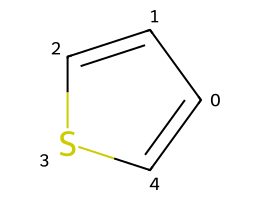

In [4]:
def draw_with_indices(mol, size=(260, 200)):
    d = Draw.rdMolDraw2D.MolDraw2DCairo(*size)
    d.drawOptions().addAtomIndices = True
    d.DrawMolecule(mol); d.FinishDrawing()
    from IPython.display import Image
    return Image(d.GetDrawingText())

thiophene = Chem.MolFromSmiles("c1ccsc1")
draw_with_indices(thiophene)

### 2.1 节点特征（原子特征）

📘 每个原子用一个向量描述。常用的做法是**独热编码**（one-hot）：比如元素，列表 `[C, N, O, S, …, 其他]` 里是哪个，哪一位就是 1，其余是 0。

| 特征 | 取值 |
|---|---|
| 元素 | C、N、O、S、F、Cl、Br、I、P、其他 |
| 度（连了几个重原子） | 0–4、其他 |
| 连接的氢原子数 | 0–3、其他 |
| 形式电荷 | -1、0、+1、其他 |
| 杂化方式 | sp、sp²、sp³、其他 |
| 是否芳香 | 0 / 1 |
| 是否在环上 | 0 / 1 |

In [5]:
ELEMENTS = ["C", "N", "O", "S", "F", "Cl", "Br", "I", "P"]
HYBRIDIZATIONS = [Chem.HybridizationType.SP, Chem.HybridizationType.SP2, Chem.HybridizationType.SP3]

def one_hot(value, choices):
    """value 在 choices 里的位置记 1；不在列表里就把最后一位"其他"记 1"""
    return [float(value == c) for c in choices] + [float(value not in choices)]

def atom_features(atom):
    return (one_hot(atom.GetSymbol(), ELEMENTS)
            + one_hot(atom.GetDegree(), [0, 1, 2, 3, 4])
            + one_hot(atom.GetTotalNumHs(), [0, 1, 2, 3])
            + one_hot(atom.GetFormalCharge(), [-1, 0, 1])
            + one_hot(atom.GetHybridization(), HYBRIDIZATIONS)
            + [float(atom.GetIsAromatic()), float(atom.IsInRing())])

for atom in thiophene.GetAtoms():
    print(atom.GetIdx(), atom.GetSymbol(), atom_features(atom))
print("每个原子的特征数:", len(atom_features(thiophene.GetAtomWithIdx(0))))

0 C [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0]
1 C [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0]
2 C [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0]
3 S [0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0]
4 C [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 1.0, 1.0]
每个原子的特征数: 31


🤔 原子 0 和 S 相邻（噻吩的 **α 位**），原子 1 不和 S 相邻（**β 位**）。它们的特征向量有什么不同？

📘 仔细比一比：两个向量**完全一样**！元素、度、氢数、杂化、芳香性都相同。单看自身特征，模型分不出 α 碳和 β 碳。

可是化学家都知道，噻吩的 α 位和 β 位反应活性差别很大，聚噻吩就是通过 α 位连起来的。**一个原子的"身份"不光取决于它自己，还取决于它的邻居。** 这正是第 3 节"消息传递"要解决的问题。

### 2.2 边特征（键特征）

In [6]:
BOND_TYPES = [Chem.BondType.SINGLE, Chem.BondType.DOUBLE, Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]

def bond_features(bond):
    return ([float(bond.GetBondType() == t) for t in BOND_TYPES]
            + [float(bond.GetIsConjugated()), float(bond.IsInRing())])

for bond in thiophene.GetBonds():
    print(f"键 {bond.GetIdx()}: 原子 {bond.GetBeginAtomIdx()}-{bond.GetEndAtomIdx()}, {bond.GetBondType()}, 特征 {bond_features(bond)}")

键 0: 原子 0-1, AROMATIC, 特征 [0.0, 0.0, 0.0, 1.0, 1.0, 1.0]
键 1: 原子 1-2, AROMATIC, 特征 [0.0, 0.0, 0.0, 1.0, 1.0, 1.0]
键 2: 原子 2-3, AROMATIC, 特征 [0.0, 0.0, 0.0, 1.0, 1.0, 1.0]
键 3: 原子 3-4, AROMATIC, 特征 [0.0, 0.0, 0.0, 1.0, 1.0, 1.0]
键 4: 原子 4-0, AROMATIC, 特征 [0.0, 0.0, 0.0, 1.0, 1.0, 1.0]


### 2.3 `edge_index`：用两行列表描述"谁连着谁"

📘 描述连接关系有两种办法：

- **邻接矩阵** $A$：$N \times N$ 的矩阵，$A_{ij} = 1$ 表示原子 $i$ 和 $j$ 之间有键。简单，但大部分元素是 0，浪费空间。
- **edge_index**：一个 $2 \times$ 边数 的数组，每一列是一条边的 (起点, 终点)。因为键是无向的，每根键要**正反各写一次**。PyG 等库都用这种格式。

In [7]:
print("邻接矩阵:\n", Chem.GetAdjacencyMatrix(thiophene))

src, dst = [], []
for bond in thiophene.GetBonds():
    i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
    src += [i, j]      # i -> j 和 j -> i 各一条
    dst += [j, i]
print("edge_index:\n", np.array([src, dst]))

邻接矩阵:
 [[0 1 0 0 1]
 [1 0 1 0 0]
 [0 1 0 1 0]
 [0 0 1 0 1]
 [1 0 0 1 0]]
edge_index:
 [[0 1 1 2 2 3 3 4 4 0]
 [1 0 2 1 3 2 4 3 0 4]]


▶️ 把这些打包成一个函数，以后任何分子都能变成图：

In [8]:
N_ATOM_FEATURES = len(atom_features(thiophene.GetAtomWithIdx(0)))
N_BOND_FEATURES = len(bond_features(thiophene.GetBondWithIdx(0)))

def mol_to_graph(mol):
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float32)
    src, dst, edge_attr = [], [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        f = bond_features(bond)
        src += [i, j]; dst += [j, i]; edge_attr += [f, f]
    return {
        "x": x,                                                                  # (原子数, 31)
        "edge_index": torch.tensor([src, dst], dtype=torch.long).reshape(2, -1),  # (2, 2×键数)
        "edge_attr": torch.tensor(edge_attr, dtype=torch.float32).reshape(-1, N_BOND_FEATURES),  # (2×键数, 6)
    }

g = mol_to_graph(thiophene)
{k: tuple(v.shape) for k, v in g.items()}

{'x': (5, 31), 'edge_index': (2, 10), 'edge_attr': (10, 6)}

### 🏋️ 练习 10a-1

BTBT（[1]苯并噻吩并[3,2-b][1]苯并噻吩）是一个经典的 p 型有机半导体核，SMILES 是 `c1ccc2c(c1)sc1c3ccccc3sc21`。

1. 用 `mol_to_graph` 把它变成图，打印 `x`、`edge_index`、`edge_attr` 的形状；
2. 先**手算**：BTBT 有几个重原子、几根键？`edge_index` 应该有几列？和程序的结果对得上吗？
3. 统计一下，这些原子里有几个是"在环上的芳香碳"？（提示：`x` 的最后两列，再加上元素那一位）

In [ ]:
# 在这里写你的代码

---
## 3. 消息传递

📘 GNN 的核心思想很直观：**每个原子向邻居"打听"消息，用打听到的信息更新自己。** 重复几轮，每个原子就知道了自己周围的化学环境。

一轮消息传递（一层 GNN）分三步：

1. **发送消息**：每个邻居 $j$ 根据自己的状态 $h_j$ 和键的特征 $e_{ij}$ 生成一条消息 $m_{j \to i} = M(h_j, e_{ij})$；
2. **聚合**：把所有邻居的消息加起来 $m_i = \sum_{j \in N(i)} m_{j \to i}$。用"求和"是因为邻居没有先后顺序，求和与顺序无关；
3. **更新**：结合自己原来的状态和收到的消息，算出新状态 $h_i' = U(h_i, m_i)$。

$M$ 和 $U$ 都是小的神经网络，它们的参数就是 GNN 要学习的东西。**所有原子共用同一套 $M$ 和 $U$**，所以不管分子有 5 个原子还是 500 个，参数个数都一样。

### 3.1 手算一遍

📘 先不用神经网络，看看信息是怎么传播的。用 2,2'-联噻吩（聚噻吩的最小单元），只给**一个**硫原子打上标记 1，其余原子是 0。每一轮规则很简单：**新值 = 自己的值 + 所有邻居的值之和**，用邻接矩阵写就是 $h' = h + A h$。

🤔 第 1 轮之后，哪些原子的值不再是 0？第 2 轮之后呢？

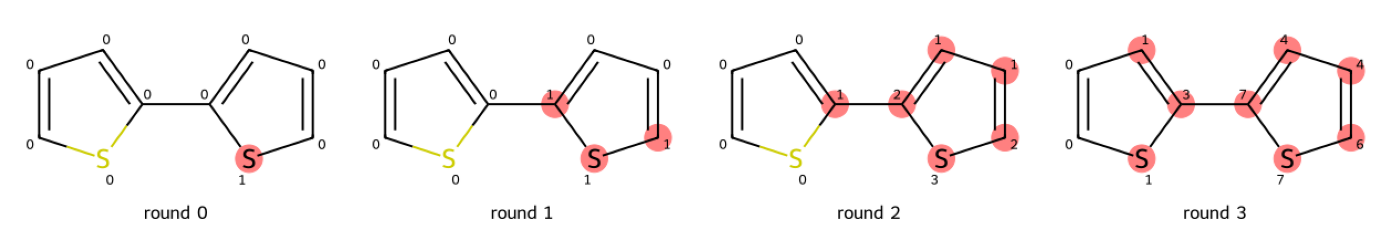

In [9]:
bithiophene = Chem.MolFromSmiles("s1cccc1-c1cccs1")
A = Chem.GetAdjacencyMatrix(bithiophene)
h = np.zeros(bithiophene.GetNumAtoms())
h[0] = 1.0                                   # 只有原子 0（第一个 S）带着"消息"

def draw_values(mol, values, title):
    m = Chem.Mol(mol)
    for atom, v in zip(m.GetAtoms(), values):
        atom.SetProp("atomNote", f"{v:g}")
    highlight = [i for i, v in enumerate(values) if v > 0]
    return Draw.MolToImage(m, size=(300, 200), highlightAtoms=highlight, legend=title)

images = [draw_values(bithiophene, h, "round 0")]
for t in range(1, 4):
    h = h + A @ h                            # 一轮"消息传递"
    images.append(draw_values(bithiophene, h, f"round {t}"))

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, img in zip(axes, images):
    ax.imshow(img); ax.axis("off")
plt.tight_layout(); plt.show()

📘 每多一轮，"知道这个硫原子存在"的范围就向外扩一圈化学键：

- 第 1 轮：只有和 S 直接相连的两个 **α 碳**；
- 第 2 轮：再往外一圈，两个 **β 碳**，以及另一个环上通过单键连过来的那个碳；
- 第 3 轮：已经传到另一个噻吩环的硫原子。

经过 $L$ 轮，每个原子"看得到"距离 $L$ 根键以内的所有原子。这个范围叫**感受野**（receptive field）。现在 α 碳和 β 碳的值不一样了：**它们终于能被区分开**。

💡 这和第一部分的 Morgan 指纹（ECFP）是同一个思路！半径为 2 的 Morgan 指纹，就是在每个原子周围看 2 根键的范围，然后把看到的子结构哈希成比特。**GNN 可以看成"可学习的"Morgan 指纹**：不是用固定规则哈希，而是用神经网络学出每个局部环境该怎么编码。

---
## 4. 读出（readout）和置换不变性

📘 消息传递之后，每个**原子**有了一个向量 $h_i$。可我们要预测的是整个**分子**的 logS，需要把所有原子的向量合成一个：这一步叫**读出**（readout）或**池化**（pooling）。常用的有：

- 求和：$h_G = \sum_i h_i$
- 平均：$h_G = \frac{1}{N} \sum_i h_i$

然后把 $h_G$ 送进一个普通的 MLP，输出 logS。

🤔 为什么不能把所有原子的向量**拼接**成一个长向量，再送进 MLP？

📘 两个原因：(1) 不同分子原子数不一样，拼出来长度不同；(2) 拼接的结果依赖原子编号的顺序，同一个分子换个编号就得到不同的输入。而求和、平均与顺序无关，这叫**置换不变性**（permutation invariance）。消息传递里用求和聚合邻居也是这个道理。**这就是 GNN 的归纳偏置：原子的编号顺序不应该影响预测。**

第 5 节写好模型后，我们会亲手验证这一点。

---
## 5. 用 PyTorch 写一个图神经网络

### 5.1 一层消息传递

📘 把第 3 节的三步翻译成代码。关键是 `index_add_`：把每条边上的消息**加到**终点原子上，这一行就完成了"聚合"。

In [10]:
class MessagePassingLayer(nn.Module):
    def __init__(self, hidden_size, n_bond_features):
        super().__init__()
        self.message = nn.Linear(hidden_size + n_bond_features, hidden_size)   # M：邻居状态 + 键特征 -> 消息
        self.update = nn.Linear(2 * hidden_size, hidden_size)                   # U：自己的状态 + 收到的消息 -> 新状态

    def forward(self, h, edge_index, edge_attr):
        src, dst = edge_index
        # 1. 发送消息：每条边 src -> dst 生成一条消息
        messages = torch.relu(self.message(torch.cat([h[src], edge_attr], dim=1)))
        # 2. 聚合：把消息加到终点原子上
        aggregated = torch.zeros_like(h).index_add_(0, dst, messages)
        # 3. 更新
        return torch.relu(self.update(torch.cat([h, aggregated], dim=1)))

### 5.2 一次处理很多个分子：批处理

📘 07a 里一个小批就是一个 $64 \times 17$ 的矩阵。可每个分子的原子数不同，没法直接堆成矩阵。

GNN 的标准技巧：**把一批分子拼成一张"大图"**。它们之间没有边，所以消息不会串门。只需要：

- 把所有原子的特征上下拼起来；
- 第 $k$ 个分子的原子编号整体加上前面所有分子的原子总数（偏移）；
- 记下每个原子属于第几个分子（`batch` 向量），读出时按它把原子加回各自的分子。

In [11]:
def collate(graphs):
    xs, edge_indices, edge_attrs, batch = [], [], [], []
    offset = 0
    for k, g in enumerate(graphs):
        n_atoms = g["x"].shape[0]
        xs.append(g["x"])
        edge_indices.append(g["edge_index"] + offset)       # 原子编号整体平移
        edge_attrs.append(g["edge_attr"])
        batch.append(torch.full((n_atoms,), k))              # 这些原子属于第 k 个分子
        offset += n_atoms
    return {"x": torch.cat(xs), "edge_index": torch.cat(edge_indices, dim=1),
            "edge_attr": torch.cat(edge_attrs), "batch": torch.cat(batch), "num_graphs": len(graphs)}

demo = collate([mol_to_graph(thiophene), mol_to_graph(bithiophene)])
print("原子总数:", demo["x"].shape[0], "（5 + 10）")
print("batch 向量:", demo["batch"].tolist())

原子总数: 15 （5 + 10）
batch 向量: [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


### 5.3 完整的模型

📘 结构：

```
原子特征 (31) ──嵌入层──► h (64) ──消息传递 × L 层──► h (64) ──读出(求和)──► h_G (64) ──MLP──► logS
```

In [12]:
class SolubilityGNN(nn.Module):
    def __init__(self, hidden_size=64, n_layers=3, readout="sum"):
        super().__init__()
        self.readout = readout
        self.embed = nn.Linear(N_ATOM_FEATURES, hidden_size)
        self.layers = nn.ModuleList([MessagePassingLayer(hidden_size, N_BOND_FEATURES) for _ in range(n_layers)])
        self.head = nn.Sequential(nn.Linear(hidden_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, 1))

    def forward(self, g):
        h = torch.relu(self.embed(g["x"]))
        for layer in self.layers:
            h = layer(h, g["edge_index"], g["edge_attr"])
        # 读出：按 batch 向量把原子加回各自的分子
        h_graph = torch.zeros(g["num_graphs"], h.shape[1]).index_add_(0, g["batch"], h)
        if self.readout == "mean":
            n_atoms = torch.bincount(g["batch"], minlength=g["num_graphs"]).clamp(min=1)
            h_graph = h_graph / n_atoms.unsqueeze(1)
        return self.head(h_graph).squeeze(1)

set_seed(0)
gnn = SolubilityGNN()
print("参数总数:", sum(p.numel() for p in gnn.parameters()))

参数总数: 44673


### 5.4 验证置换不变性

▶️ 把 3-甲基噻吩的原子编号随机打乱，送进**还没训练**的 GNN。邻接矩阵变了，输出会变吗？

In [13]:
mol = Chem.MolFromSmiles("Cc1ccsc1")
order = [3, 5, 0, 2, 4, 1]                       # ✏️ 换一种顺序（0–5 每个数用一次）
shuffled = Chem.RenumberAtoms(mol, order)

print("原来的邻接矩阵:\n", Chem.GetAdjacencyMatrix(mol))
print("打乱后的邻接矩阵:\n", Chem.GetAdjacencyMatrix(shuffled))

gnn.eval()
with torch.no_grad():
    out1 = gnn(collate([mol_to_graph(mol)])).item()
    out2 = gnn(collate([mol_to_graph(shuffled)])).item()
print(f"GNN 输出: {out1:.6f} vs {out2:.6f}")

原来的邻接矩阵:
 [[0 1 0 0 0 0]
 [1 0 1 0 0 1]
 [0 1 0 1 0 0]
 [0 0 1 0 1 0]
 [0 0 0 1 0 1]
 [0 1 0 0 1 0]]
打乱后的邻接矩阵:
 [[0 0 0 1 1 0]
 [0 0 0 0 1 1]
 [0 0 0 0 0 1]
 [1 0 0 0 0 1]
 [1 1 0 0 0 0]
 [0 1 1 1 0 0]]
GNN 输出: 0.027382 vs 0.027382


📘 输入的矩阵变了，输出却一样（最多差在小数点后第 6、7 位，那是浮点运算的舍入误差）。**这个性质是模型结构保证的，不需要从数据里学。** 这就是好的归纳偏置的价值。

---
## 6. 训练

### 6.1 准备数据

📘 把 9480 个分子全部转成图（几秒钟）。划分方式和 07a **完全一样**：同样的 `random_state` 和 `test_size`，测试集就是同一批分子。

In [15]:
if "mol" not in df.columns:
    df = df.copy()
    df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)
    df = df[df["mol"].notna()].reset_index(drop=True)

y = df["Solubility"].to_numpy()
graphs = [mol_to_graph(m) for m in df["mol"]]
y_t = torch.tensor(y, dtype=torch.float32)

idx = np.arange(len(df))
idx_trval, idx_test = train_test_split(idx, test_size=0.2, random_state=42)
idx_train, idx_valid = train_test_split(idx_trval, test_size=0.1, random_state=42)
print("训练:", len(idx_train), " 验证:", len(idx_valid), " 测试:", len(idx_test))
print("平均每个分子的重原子数:", round(np.mean([g["x"].shape[0] for g in graphs]), 1))

训练: 6825  验证: 759  测试: 1896
平均每个分子的重原子数: 17.4


### 6.2 训练循环

📘 和 07a 的训练循环几乎一样，只是"一个小批"从矩阵变成了 `collate` 拼出来的大图。

In [16]:
loss_fn = nn.MSELoss()

def iterate_batches(indices, batch_size=64, shuffle=False):
    if shuffle:
        indices = np.random.permutation(indices)
    for start in range(0, len(indices), batch_size):
        ids = indices[start:start + batch_size]
        yield collate([graphs[i] for i in ids]), y_t[ids]

def predict(model, indices):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(g) for g, _ in iterate_batches(indices, batch_size=512)])

def rmse(model, indices):
    return torch.sqrt(loss_fn(predict(model, indices), y_t[indices])).item()

def fit(model, n_epochs=40, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train": [], "valid": []}
    best_valid, best_state = float("inf"), None
    for epoch in range(n_epochs):
        model.train()
        total, n = 0.0, 0
        for g, yb in iterate_batches(idx_train, shuffle=True):
            loss = loss_fn(model(g), yb)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(yb); n += len(yb)
        history["train"].append((total / n) ** 0.5)    # 训练误差：这一轮各小批的平均，省得再算一遍
        history["valid"].append(rmse(model, idx_valid))
        if history["valid"][-1] < best_valid:
            best_valid, best_state = history["valid"][-1], copy.deepcopy(model.state_dict())
        if epoch % 10 == 9:
            print(f"epoch {epoch + 1:3d}: 训练 RMSE {history['train'][-1]:.2f}, 验证 RMSE {history['valid'][-1]:.2f}")
    model.load_state_dict(best_state)                  # 早停：装回验证集上最好的参数
    return history

▶️ 训练 60 轮（CPU 上大约 1–2 分钟）：

epoch  10: 训练 RMSE 1.47, 验证 RMSE 2.11
epoch  20: 训练 RMSE 1.10, 验证 RMSE 1.47
epoch  30: 训练 RMSE 0.96, 验证 RMSE 1.12
epoch  40: 训练 RMSE 0.89, 验证 RMSE 1.07
epoch  50: 训练 RMSE 0.83, 验证 RMSE 1.05
epoch  60: 训练 RMSE 0.78, 验证 RMSE 1.01


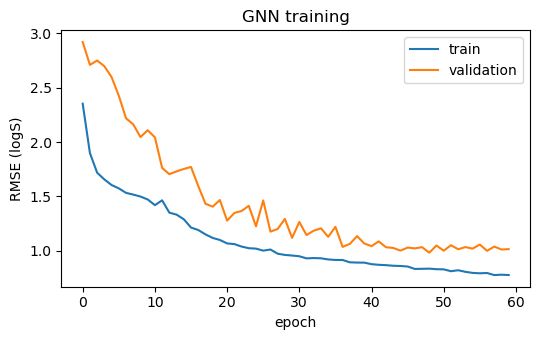

In [17]:
set_seed(0)
gnn = SolubilityGNN(hidden_size=64, n_layers=3)      # ✏️
history = fit(gnn, n_epochs=60)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(history["train"], label="train"); ax.plot(history["valid"], label="validation")
ax.set_xlabel("epoch"); ax.set_ylabel("RMSE (logS)"); ax.set_title("GNN training"); ax.legend()
plt.tight_layout(); plt.show()

In [18]:
gnn_test_rmse = rmse(gnn, idx_test)
print(f"GNN 测试 RMSE: {gnn_test_rmse:.2f}")

GNN 测试 RMSE: 1.03


### 6.3 和之前的模型比较

| 模型 | 输入 | 测试 RMSE |
|---|---|---|
| 永远预测平均值 | — | 2.42 |
| 线性回归 | 17 个描述符 | 1.64 |
| 随机森林 | 17 个描述符 | 1.17 |
| MLP（07a） | 17 个描述符 | 1.17–1.19 |
| 随机森林 | 描述符 + 计数指纹（02a） | 1.11 |
| **GNN** | **只有原子和键** | **1.04** |

🤔 GNN 的输入里**没有** logP、没有分子量、没有 TPSA，只有每个原子是什么元素、连着谁。它却比用了这些描述符的模型都好。它是怎么做到的？

📘 GNN 自己从结构里"学出了"需要的特征。比如 MolLogP 本身就是按原子类型加和算出来的（Crippen 方法），而"原子类型 + 邻居"恰好是 GNN 每一层在做的事；分子大小则来自求和读出（原子越多，向量的"总量"越大）。**这就是深度学习"自己学特征"的含义。**

✏️ 训练曲线的验证误差到第 60 轮还在往下走。把 `n_epochs` 改成 100 试试（要多等一分钟左右）。

💡 这里的提升（约 0.1）不算巨大，而且 GNN 也比随机森林更花时间、更依赖调参。数据只有几千个的时候，**随机森林 + 好的指纹**依然是一个很强、很省事的基线。实际项目里两者都应该试。

▶️ 对角线图：

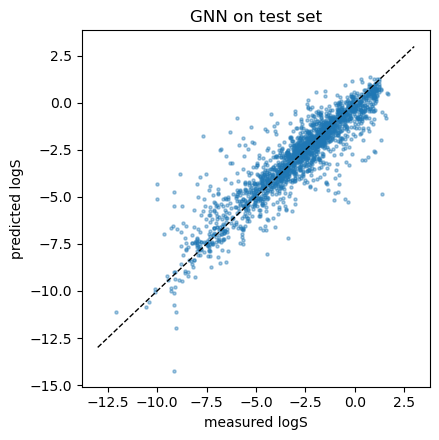

In [19]:
y_pred = predict(gnn, idx_test).numpy()
plt.figure(figsize=(4.5, 4.5))
plt.scatter(y[idx_test], y_pred, s=5, alpha=0.4)
plt.plot([-13, 3], [-13, 3], "k--", lw=1)
plt.xlabel("measured logS"); plt.ylabel("predicted logS"); plt.title("GNN on test set")
plt.tight_layout(); plt.show()

### 🏋️ 练习 10a-2

感受野和层数有关。分别训练 `n_layers=1` 和 `n_layers=5` 的 GNN（各 40 轮），比较测试 RMSE。层数越多越好吗？

💡 层数太多会出现**过平滑**（over-smoothing）：每一层都把邻居的信息混进来，混得太多，所有原子的向量越来越像，反而分不清了。分子 GNN 一般用 3–6 层。

In [ ]:
# 在这里写你的代码

---
## 7. 并苯系列：GNN 能外推吗？

📘 02a 第 9 节，随机森林把并五苯预测得和并四苯差不多（-8.38 vs -8.27）：并五苯在训练数据的"边缘之外"，而随机森林的预测不会超出训练集里 y 的范围。

🤔 GNN 呢？

In [20]:
acenes = {
    "benzene": "c1ccccc1",
    "naphthalene": "c1ccc2ccccc2c1",
    "anthracene": "c1ccc2cc3ccccc3cc2c1",
    "tetracene": "c1ccc2cc3cc4ccccc4cc3cc2c1",
    "pentacene": "c1ccc2cc3cc4cc5ccccc5cc4cc3cc2c1",
}
rf_02a = [-1.69, -4.14, -5.96, -8.27, -8.38]          # 02a 第 9 节随机森林的结果

canon_smiles = df["mol"].apply(Chem.MolToSmiles)
canon_to_logS = dict(zip(canon_smiles, df["Solubility"]))
train_smiles = set(canon_smiles.iloc[idx_train])

def gnn_predict_smiles(model, smiles_list):
    model.eval()
    with torch.no_grad():
        return model(collate([mol_to_graph(Chem.MolFromSmiles(s)) for s in smiles_list])).numpy()

acene_table = pd.DataFrame({
    "molecule": list(acenes),
    "rings": range(1, 6),
    "in training set": [Chem.CanonSmiles(s) in train_smiles for s in acenes.values()],
    "measured logS": [canon_to_logS.get(Chem.CanonSmiles(s), np.nan) for s in acenes.values()],
    "random forest (02a)": rf_02a,
    "GNN": gnn_predict_smiles(gnn, list(acenes.values())),
}).round(2)
acene_table

,molecule,rings,in training set,measured logS,random forest (02a),GNN
0,benzene,1,True,-1.64,-1.69,-1.28
1,naphthalene,2,True,-4.31,-4.14,-3.61
2,anthracene,3,True,-6.44,-5.96,-5.77
3,tetracene,4,True,-8.60,-8.27,-7.15
4,pentacene,5,False,NaN,-8.38,-7.69


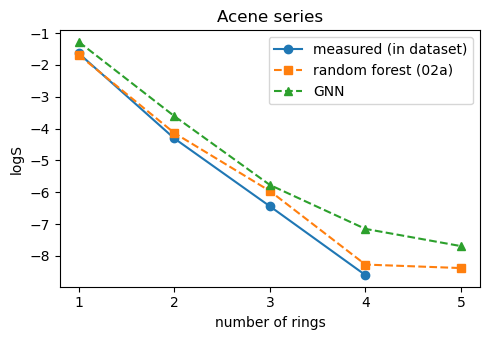

In [21]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(acene_table["rings"], acene_table["measured logS"], "o-", label="measured (in dataset)")
ax.plot(acene_table["rings"], acene_table["random forest (02a)"], "s--", label="random forest (02a)")
ax.plot(acene_table["rings"], acene_table["GNN"], "^--", label="GNN")
ax.set_xticks(range(1, 6))
ax.set_xlabel("number of rings"); ax.set_ylabel("logS"); ax.set_title("Acene series"); ax.legend()
plt.tight_layout(); plt.show()

📘 两个有意思的现象：

1. **在训练集里的分子**（苯到并四苯），随机森林几乎和实验值重合，GNN 反而偏高了 0.3–1.4。随机森林的训练 RMSE 只有 0.42，它基本把训练集"背"下来了；GNN 没有背得那么死。
2. **不在训练集里的并五苯**，GNN 预测它比并四苯更难溶（约 -7.8 vs -7.2），延续了"每多一个环，溶解度降一截"的趋势；随机森林在这里几乎走平（-8.38 vs -8.27）。

原因是求和读出：并五苯比并四苯多 4 个碳原子，每个碳原子都对 $h_G$ 贡献一份，GNN 的预测自然会继续往下走。这种结构上的"可加性"让 GNN 更有可能外推，有点像化学里的**基团贡献法**。

⚠️ 但别高兴得太早：

- 看 `in training set` 那一列：苯到并四苯都是模型训练时**见过**的。只有并五苯是真正的外推。
- 趋势对了，数值却不一定对：GNN 对并四苯已经偏高了约 1.4，对并五苯很可能也偏高。
- 并五苯是否"真的"在这个位置，我们没有实验值可以核对。外推的结果永远要打个问号，02b 的教训依然有效。
- `n_layers=3` 时，并四苯和并五苯**中间**那些碳原子看到的 3 根键以内的环境完全一样。两个分子的差别主要体现在"多了几个同样的原子"。

### 🏋️ 练习 10a-3

把读出从求和换成平均（`SolubilityGNN(readout="mean")`），训练 60 轮，再预测并苯系列。

1. 测试 RMSE 变了多少？
2. 并苯系列的趋势还在吗？并四苯和并五苯的预测差多少？
3. 用"平均"和"求和"的区别解释你看到的现象。（提示：苯、萘、……、并五苯里，每个原子的平均环境有多大差别？）

In [ ]:
# 在这里写你的代码

---
## 小结

| 学到了 | 代码 / 要点 |
|---|---|
| 归纳偏置 | 模型结构里的先验假设；分子 → 图，原子编号顺序不应影响结果 |
| 分子图 | 节点特征 `x`、边 `edge_index`（每根键正反各一次）、边特征 `edge_attr` |
| 消息传递 | 发送 → 聚合（求和）→ 更新；$L$ 层 = 看得到 $L$ 根键以内 |
| 和 Morgan 指纹的关系 | GNN ≈ 可学习的 Morgan 指纹 |
| 读出 | 求和或平均，保证置换不变性 |
| 批处理 | 一批分子拼成一张不相连的大图，用 `batch` 向量记录归属 |
| 结果 | 只用原子和键，GNN 测试 RMSE 好于所有描述符模型 |

💡 实际研究中不需要每次都手写这些。常用的库有：

- [PyTorch Geometric](https://pytorch-geometric.readthedocs.io/)（PyG）：几十种现成的 GNN 层，`edge_index` 格式就是它定的；
- [DGL](https://www.dgl.ai/)：另一个流行的图神经网络库；
- [chemprop](https://github.com/chemprop/chemprop)：专门为分子性质预测做的 GNN，**一行命令**就能训练。下一节 **10b** 就用它。